## 6 · Model selection

### By:
Sofía Arango Patiño

### Date:
2026-11-03

### Description:

Sixth step of the proof of concept ([issue #6](https://github.com/modsiw-mona/anomaly_detection_ato/issues/6);
CRISP-DM phase 4, *modelling*; thesis objective **OE3**). The bar comes from issue #5: the logistic regression,
PR-AUC 0.023 [0.013–0.050] pooled, recall at a 1% alert budget 0.80.

1. **What the takeovers look like** — a profile of the development takeovers, which shapes everything below.
2. **Model families** — supervised (logistic regression, random forest, three gradient-boosting implementations),
   unsupervised (Isolation Forest) and PU bagging, on the issue #4 features.
3. **New features** from the profile — attacker infrastructure (`campaign`) and impossible travel (`travel`).
4. **Campaign balancing** — one campaign is most of the labels; does weighting it down help the rest?
5. **Leave-campaign-out** — does the model detect a campaign it never saw in training?
6. **Ablations** — RTT, synthesis artefacts, fine geography, time, global rarity: tested, not assumed.
7. **Tuning of the two best families, learning curves and scalability, finalists on all 15 folds**, and the
   selected model, saved as a `.joblib` pipeline for issue #7.

This is research, not a replication (development plan, decisions of 2026-11-03): earlier methods (Freeman et al.,
2016) are comparison points, and the data chooses. The test side stays closed until issue #7.

## 📚 Import libraries

In [1]:
import sys
from pathlib import Path

# Make the project's `src/` importable, wherever the notebook is opened from.
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

from data.datasets import load_dataset_config
from data.features import DEFAULT_GROUPS, feature_columns
from data.split import load_side
from model import selection
from model.evaluation import assign_folds, bootstrap_pr_auc, evaluate
from model.selection import (
    candidate,
    fit_isolation_forest,
    fit_pu_bagging,
    fold_per_login,
    group_metrics,
    out_of_fold,
    train_supervised,
)

warnings.filterwarnings("ignore", message="X does not have valid feature names")
pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(50)
pl.Config.set_tbl_width_chars(200)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 of the validated palette
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
        "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
    }
)  # fmt: skip


def subtitle(ax: plt.Axes, text: str) -> None:
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")

## 💾 Load data — development side only

In [3]:
config = load_dataset_config("rba")
data_dir = REPO_ROOT / "data"
dev = load_side(config, data_dir, "dev").collect()
N_REPEATS, N_FOLDS = 3, 5
folds = assign_folds(dev, n_folds=N_FOLDS, n_repeats=N_REPEATS)  # same folds as issue #5
fold = {r: fold_per_login(dev, folds, f"fold_{r}") for r in range(N_REPEATS)}
y = dev["label_ato"].to_numpy()
romania = (dev["country"] == "RO").to_numpy()
groups = {"Romania": romania, "other": ~romania}
print(
    f"development side: {dev.height:,} logins, {int(y.sum())} takeovers ({int((y & romania).sum())} from RO)"
)

development side: 7,868,084 logins, 112 takeovers (62 from RO)


## 🕵️ 1 · What the takeovers look like

The EDA (issue #3) compared takeovers with legitimate logins as a whole. Looking at the takeovers themselves, one
group stands out: **62 of the 112 development takeovers come from one country, `RO`** (79 of 141 in the whole
file, February – November 2020; the dataset card has the details). The companion paper notes the same: most
identified attacks came "from a particular ASN and a country that was far from the online service's main country"
(Wiefling et al., 2022, §5). Side by side:

In [4]:
raw = pl.scan_parquet(data_dir / "02_intermediate" / f"{config.name}.parquet").select(
    "event_id", "asn", "user_agent"
)
profile = dev.join(raw.collect(), on="event_id", how="left")
SIGNALS = ["first_success", "new_country", "new_asn", "new_device_type", "new_browser", "attack_ip"]
segment = (
    pl.when(~pl.col("label_ato"))
    .then(pl.lit("legitimate"))
    .when(pl.col("country") == "RO")
    .then(pl.lit("takeover · Romania"))
    .otherwise(pl.lit("takeover · other"))
)
(
    profile.with_columns(segment.alias("segment"))
    .group_by("segment")
    .agg(
        pl.len().alias("logins"),
        *(pl.col(s).cast(pl.Float64).mean().round(3).alias(s) for s in SIGNALS),
        pl.col("hours_since_prev_success").median().round(0).alias("median hours since last login"),
    )
    .sort("segment")
)

segment,logins,first_success,new_country,new_asn,new_device_type,new_browser,attack_ip,median hours since last login
str,u32,f64,f64,f64,f64,f64,f64,f64
"""legitimate""",7867972,0.282,0.008,0.108,0.093,0.382,0.061,100.0
"""takeover · Romania""",62,0.403,0.919,0.973,0.378,0.865,0.806,937.0
"""takeover · other""",50,0.32,0.647,0.706,0.265,0.647,0.18,62.0


In [5]:
ro_takeovers = profile.filter(pl.col("label_ato") & (pl.col("country") == "RO"))
other_takeovers = profile.filter(pl.col("label_ato") & (pl.col("country") != "RO"))
print(
    "Romania: logins sharing the most common user-agent string:",
    ro_takeovers["user_agent"].value_counts()["count"].max(),
    "of",
    ro_takeovers.height,
)
print(
    "Romania: distinct ASNs:",
    ro_takeovers["asn"].n_unique(),
    "· other takeovers: distinct ASNs:",
    other_takeovers["asn"].n_unique(),
)
print(
    "other takeovers: most frequent ASN accounts for",
    other_takeovers["asn"].value_counts()["count"].max(),
    "of",
    other_takeovers.height,
)

Romania: logins sharing the most common user-agent string: 41 of 62
Romania: distinct ASNs: 25 · other takeovers: distinct ASNs: 22
other takeovers: most frequent ASN accounts for 11 of 50


**Reading.** The Romania takeovers look like **one campaign**: a country new for the victim (92%), attack IPs
(81%), mostly one identical user-agent string (41 of 62), 25 networks of which a few carry most of it, and
**dormant accounts** (a median of ~39 days since the last login, against ~4 for legitimate logins). The other
takeovers show the same signals, weaker (attack IPs only 18%), plus a smaller cluster on one network (11 of 50).

Two consequences shape the rest of this notebook:

* every result is reported for **Romania and the other takeovers separately**, and a **leave-campaign-out** test
  checks that a model is not just recognising one campaign;
* new features describe **attacker infrastructure** shared across victims (section 3).

A note on what is *not* done: the RTT column (round-trip time) would be the natural proxy detector, an RTT too long
for the claimed location, but the authors reassigned real RTTs at random among logins of the same location, which
erases exactly that mismatch; and outside data about networks (hosting providers, VPN lists) would attach real-world
facts to synthetic values (ASN 29695 appears 7.7 M times in Norway and 434 k times in Brazil). Both decisions are in
the development plan (section 5.4).

## 🧪 Experiment helpers

Every experiment trains on the other folds and scores the held-out fold (out-of-fold). Training uses every
takeover plus 5% of legitimate logins; evaluation uses the complete fold. Screening uses the 5 folds of repeat 0;
the finalists use all 15 folds (section 7).

In [6]:
BASE = feature_columns()
NEW = feature_columns((*DEFAULT_GROUPS, "campaign", "travel"))
results: list[dict] = []
oof_cache: dict[str, np.ndarray] = {}


PROGRESS = (
    data_dir / "08_reporting" / f"{config.name}_06_progress.log"
)  # follow a long run: tail -f
PROGRESS.parent.mkdir(exist_ok=True)
PROGRESS.write_text("")


def run(  # noqa: PLR0913 — one experiment, many knobs
    label: str,
    fit,
    columns,
    *,
    repeat: int = 0,
    hide=None,
    step: str = "",
    reuse: str | None = None,
) -> np.ndarray:
    if reuse is not None:  # same experiment already run under another name: copy it
        earlier = next(r for r in results if r["experiment"] == reuse and r["repeat"] == repeat)
        results.append({**earlier, "step": step, "experiment": label})
        oof_cache[f"{label} · repeat {repeat}"] = oof_cache[f"{reuse} · repeat {repeat}"]
        return oof_cache[f"{label} · repeat {repeat}"]
    with PROGRESS.open("a") as log:
        log.write(f"{time.strftime('%H:%M:%S')} start {step} · {label} · repeat {repeat}\n")
    start = time.perf_counter()
    oof = out_of_fold(dev, fold[repeat], fit, columns, hide=hide)
    per_fold = [evaluate(y[fold[repeat] == k], oof[fold[repeat] == k]) for k in range(N_FOLDS)]
    by_group = group_metrics(y, oof, groups)
    low, high = bootstrap_pr_auc(y, oof, n_boot=1_000)
    results.append(
        {
            "step": step, "experiment": label, "repeat": repeat, "columns": len(columns),
            "pr_auc": float(np.mean([m["pr_auc"] for m in per_fold])),
            "pr_auc_std": float(np.std([m["pr_auc"] for m in per_fold], ddof=1)),
            "pooled_low": low, "pooled_high": high,
            "recall_0_1pct": float(np.mean([m["recall_at_0_1pct"] for m in per_fold])),
            "recall_1pct": float(np.mean([m["recall_at_1pct"] for m in per_fold])),
            "precision_1pct": float(np.mean([m["precision_at_1pct"] for m in per_fold])),
            "pr_auc_romania": by_group["Romania"]["pr_auc"], "recall_1pct_romania": by_group["Romania"]["recall_at_1pct"],
            "pr_auc_other": by_group["other"]["pr_auc"], "recall_1pct_other": by_group["other"]["recall_at_1pct"],
            "recall_0_1pct_other": by_group["other"]["recall_at_0_1pct"],
            "seconds": round(time.perf_counter() - start),
        }
    )  # fmt: skip
    oof_cache[f"{label} · repeat {repeat}"] = oof
    return oof


SHOW = ["experiment", "pr_auc", "pooled_low", "pooled_high", "recall_0_1pct", "recall_1pct", "pr_auc_romania",
        "recall_1pct_romania", "pr_auc_other", "recall_1pct_other", "seconds"]  # fmt: skip


def table(step: str) -> pl.DataFrame:
    frame = pl.DataFrame([r for r in results if r["step"] == step])
    return frame.select(SHOW).with_columns(pl.col(pl.Float64).round(3))

## 🏁 2 · Model families

On the issue #4 features. Gradient boosting runs in three implementations: scikit-learn's
`HistGradientBoostingClassifier`, LightGBM and XGBoost (the last two need the OpenMP runtime, `brew install libomp`
on macOS). PU bagging averages 5 gradient-boosting models, each against a different sample of the "legitimate"
logins (unlabelled is not the same as legitimate). Isolation Forest never sees a label.

In [7]:
for name in selection.SUPERVISED:
    run(name, candidate(name), BASE, step="families")
run(
    "PU bagging (5 × gradient boosting)",  # noqa: RUF001
    lambda tr, cols: fit_pu_bagging(tr, cols, n_bags=5),
    BASE,
    step="families",
)
run("Isolation Forest (no labels)", fit_isolation_forest, BASE, step="families")
families = table("families")
families

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""logistic regression""",0.033,0.013,0.049,0.528,0.805,0.019,0.984,0.012,0.58,30
"""random forest""",0.398,0.292,0.467,0.778,0.876,0.505,1.0,0.071,0.72,83
"""gradient boosting""",0.366,0.267,0.432,0.787,0.849,0.458,1.0,0.065,0.66,85
"""LightGBM""",0.405,0.288,0.454,0.787,0.867,0.5,1.0,0.058,0.7,49
"""XGBoost""",0.4,0.278,0.446,0.787,0.867,0.479,1.0,0.063,0.7,37
"""PU bagging (5 × gradient boosting)""",0.428,0.303,0.479,0.796,0.867,0.523,1.0,0.072,0.72,356
"""Isolation Forest (no labels)""",0.011,0.004,0.016,0.403,0.555,0.009,0.629,0.001,0.46,134


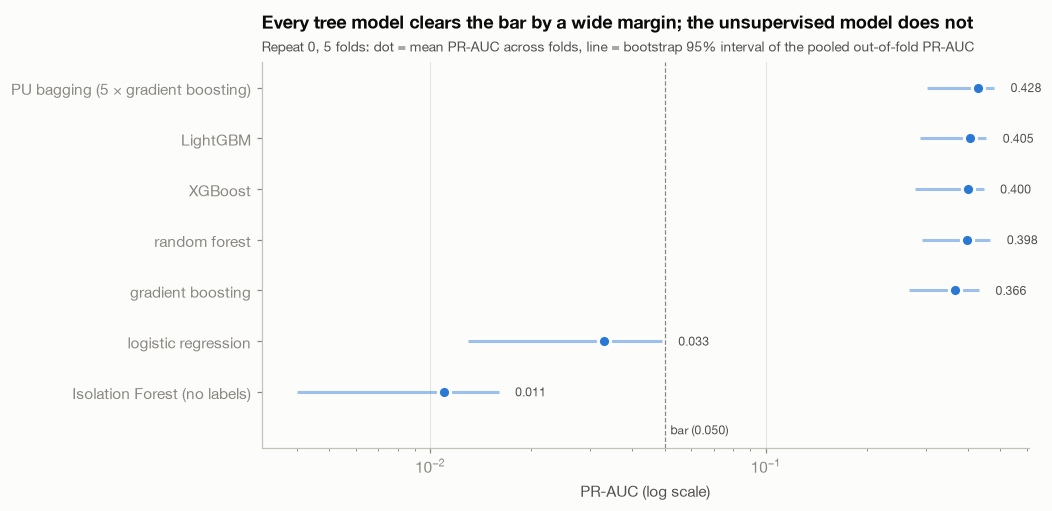

In [8]:
def interval_chart(frame: pl.DataFrame, title: str, note: str) -> None:
    frame = frame.sort("pr_auc")
    _, ax = plt.subplots(figsize=(9, 0.45 * frame.height + 1.4))
    yy = np.arange(frame.height)
    ax.hlines(yy, frame["pooled_low"], frame["pooled_high"], color=BLUE, linewidth=2, alpha=0.45)
    ax.plot(
        frame["pr_auc"],
        yy,
        "o",
        color=BLUE,
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
    )
    ax.axvline(0.050, color=MUTED, linewidth=0.8, linestyle="--")
    ax.text(0.052, -0.75, "bar (0.050)", color=INK_2, fontsize=8, va="center")
    for i, value in enumerate(frame["pr_auc"]):
        ax.text(
            max(frame["pooled_high"][i], value) * 1.12,
            i,
            f"{value:.3f}",
            color=INK_2,
            fontsize=8,
            va="center",
        )
    ax.set_xscale("log")
    ax.set_yticks(yy, frame["experiment"])
    ax.set_ylim(-1.1, frame.height - 0.5)
    ax.set_ylim(-1.1, frame.height - 0.5)
    ax.grid(axis="x")
    ax.set_xlabel("PR-AUC (log scale)")
    ax.set_title(title, pad=22)
    subtitle(ax, note)
    plt.show()


interval_chart(
    families,
    "Every tree model clears the bar by a wide margin; the unsupervised model does not",
    "Repeat 0, 5 folds: dot = mean PR-AUC across folds, line = bootstrap 95% interval of the pooled out-of-fold PR-AUC",
)

**Reading.** All tree models land close together: **PR-AUC 0.37–0.43, 11–13× the logistic regression**
(0.033 on the same folds), with overlapping intervals — the implementation matters much less than moving from a
linear model to trees. PU bagging is the highest on this repeat (0.43) but inside the others' intervals, at about
four times the cost of one model. Isolation Forest, which never sees a label, stays *below* the logistic
regression (0.011): with these features the takeovers are not simply "unusual logins", and a handful of labels
is worth more than none (in line with ADBench, Han et al., 2022).

Most of the gain is on the Romania campaign; the other takeovers improve too (recall at 1%: 58% → 72% for the
random forest), but remain the hard part.

## 🧩 3 · New features from the takeover profile

Two new feature groups (`src/data/features.py`, past-only and tested for leakage like the others):

| Group | Columns | Hypothesis |
| --- | --- | --- |
| `campaign` | share of earlier attempts from this ASN / IP that failed or came from an attack IP; attempts and failures from this ASN in the previous 24 full hours; accounts that already used this exact user agent | attackers reuse infrastructure across victims |
| `travel` | country change less than an hour after the previous successful login; countries the user had succeeded from before | impossible travel; a new country means more for a user who never travels |

In [9]:
for name in ["random forest", "LightGBM"]:
    for label, groups_added in [
        ("+ campaign", ("campaign",)),
        ("+ travel", ("travel",)),
        ("+ campaign + travel", ("campaign", "travel")),
    ]:
        run(
            f"{name} {label}",
            candidate(name),
            feature_columns((*DEFAULT_GROUPS, *groups_added)),
            step="new features",
        )
pl.concat(
    [
        families.filter(pl.col("experiment").is_in(["random forest", "LightGBM"])),
        table("new features"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest""",0.398,0.292,0.467,0.778,0.876,0.505,1.0,0.071,0.72,83
"""LightGBM""",0.405,0.288,0.454,0.787,0.867,0.5,1.0,0.058,0.7,49
"""random forest + campaign""",0.395,0.284,0.447,0.796,0.911,0.464,1.0,0.084,0.78,73
"""random forest + travel""",0.427,0.31,0.481,0.778,0.894,0.517,1.0,0.089,0.76,70
"""random forest + campaign + travel""",0.419,0.326,0.499,0.805,0.903,0.527,1.0,0.103,0.78,73
"""LightGBM + campaign""",0.382,0.261,0.421,0.787,0.885,0.444,0.984,0.063,0.74,47
"""LightGBM + travel""",0.433,0.324,0.496,0.796,0.858,0.567,1.0,0.067,0.68,46
"""LightGBM + campaign + travel""",0.421,0.305,0.478,0.787,0.893,0.514,0.984,0.085,0.76,48


**Reading.** The new groups help mostly where it is needed, on the **non-Romania** takeovers: with both
groups their PR-AUC rises from 0.071 to 0.103 (random forest) and from 0.058 to 0.085 (LightGBM), and the random
forest's recall at 1% on them from 72% to 78%; overall PR-AUC moves little (0.40 → 0.42). The differences are small next to the noise of
~50 takeovers, so the final comparison (section 7) re-checks them on all 15 folds. Both groups are kept: they encode
real attacker behaviour and cost nothing to compute.

## ⚖️ 4 · Campaign balancing

In training, the Romania takeovers outnumber all the others. `selection.campaign_weights` gives the dominant
campaign (the country with the most takeovers in the training sample) and all other takeovers the **same total
weight**; legitimate logins are untouched.

In [10]:
for name in ["random forest", "LightGBM"]:
    run(
        f"{name} + campaign + travel, campaign-balanced",
        candidate(name, balance_campaign=True),
        NEW,
        step="balancing",
    )
pl.concat(
    [
        table("new features").filter(pl.col("experiment").str.ends_with("campaign + travel")),
        table("balancing"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest + campaign + travel""",0.419,0.326,0.499,0.805,0.903,0.527,1.0,0.103,0.78,73
"""LightGBM + campaign + travel""",0.421,0.305,0.478,0.787,0.893,0.514,0.984,0.085,0.76,48
"""random forest + campaign + travel, campaign-balanc…",0.421,0.321,0.494,0.805,0.885,0.489,1.0,0.122,0.74,83
"""LightGBM + campaign + travel, campaign-balanced""",0.421,0.3,0.463,0.796,0.885,0.502,0.984,0.074,0.74,48


**Reading.** Balancing changes the *ranking* of the non-Romania takeovers more than how many are caught: for
the random forest their PR-AUC rises from 0.103 to 0.122, while their recall at 1% moves from 78% to 74% (one or
two takeovers, within noise); overall PR-AUC is unchanged (0.42). LightGBM does not benefit. On all 15 folds
(section 7) the balanced forest keeps the higher non-Romania PR-AUC (0.129 vs 0.115).

## 🧭 5 · Leave-campaign-out

The strongest test of generalisation available here: **hide one group of takeovers from training** (they are
still scored), and measure how well the model detects them anyway. A model that only memorised the Romania campaign
would fail on it once hidden.

In [11]:
leave_out = []
for name, fitter, columns in [
    ("logistic regression", candidate("logistic regression"), BASE),
    ("random forest + campaign + travel", candidate("random forest"), NEW),
]:
    seen = run(f"{name} · nothing hidden", fitter, columns, step="leave-out")
    for hidden_name, hidden in groups.items():
        oof = run(f"{name} · {hidden_name} hidden", fitter, columns, hide=hidden, step="leave-out")
        for status, scores in (("seen in training", seen), ("hidden from training", oof)):
            m = group_metrics(y, scores, {hidden_name: hidden})[hidden_name]
            leave_out.append({"model": name, "takeovers": hidden_name, "status": status, "pr_auc": m["pr_auc"],
                              "recall_0_1pct": m["recall_at_0_1pct"], "recall_1pct": m["recall_at_1pct"]})  # fmt: skip
leave_out = pl.DataFrame(leave_out).with_columns(pl.col(pl.Float64).round(3))
leave_out

model,takeovers,status,pr_auc,recall_0_1pct,recall_1pct
str,str,str,f64,f64,f64
"""logistic regression""","""Romania""","""seen in training""",0.019,0.694,0.984
"""logistic regression""","""Romania""","""hidden from training""",0.008,0.548,0.919
"""logistic regression""","""other""","""seen in training""",0.012,0.32,0.58
"""logistic regression""","""other""","""hidden from training""",0.004,0.28,0.64
"""random forest + campaign + travel""","""Romania""","""seen in training""",0.527,0.952,1.0
"""random forest + campaign + travel""","""Romania""","""hidden from training""",0.259,0.855,0.968
"""random forest + campaign + travel""","""other""","""seen in training""",0.103,0.58,0.78
"""random forest + campaign + travel""","""other""","""hidden from training""",0.01,0.46,0.62


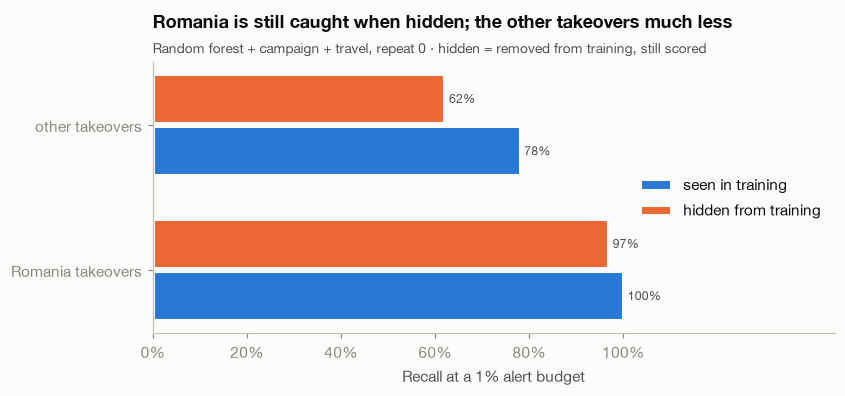

In [12]:
rf = leave_out.filter(pl.col("model").str.starts_with("random forest"))
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = ["Romania", "other"]
for offset, status, color in [
    (-0.18, "seen in training", BLUE),
    (0.18, "hidden from training", ORANGE),
]:
    values = [
        rf.filter((pl.col("takeovers") == g) & (pl.col("status") == status))["recall_1pct"][0]
        for g in labels
    ]
    bars = ax.barh(
        np.arange(2) + offset,
        values,
        height=0.34,
        color=color,
        label=status,
        edgecolor=SURFACE,
        linewidth=2,
    )
    for bar, value in zip(bars, values, strict=True):
        ax.text(
            value + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.0%}",
            va="center",
            fontsize=8,
            color=INK_2,
        )
ax.set_yticks(np.arange(2), [f"{g} takeovers" for g in labels])
ax.set_xlim(0, 1.45)
ax.set_xticks(np.linspace(0, 1, 6), [f"{v:.0%}" for v in np.linspace(0, 1, 6)])
ax.set_xlabel("Recall at a 1% alert budget")
ax.legend(loc="center right")
ax.set_title("Romania is still caught when hidden; the other takeovers much less", pad=22)
subtitle(
    ax, "Random forest + campaign + travel, repeat 0 · hidden = removed from training, still scored"
)
plt.show()

**Reading.** With the Romania campaign **removed from training**, the random forest still catches 97% of it
at a 1% budget and 86% at 0.1%: it learnt what a takeover looks like (new country, attack-IP networks, dormant
account, rare values), not "Romania".

The reverse is **much weaker**: with the other takeovers hidden, their recall at 1% falls from 78% to 62% and
their PR-AUC from 0.10 to 0.01 — they still land in the top 1% fairly often, but no longer near the top. A model
trained mostly on one campaign does not rank a *different* kind of attack highly. This is the honest limit of
these results: detection of new attack patterns rests on ~50 heterogeneous takeovers.

A second observation: with Romania hidden, the **non-Romania** PR-AUC rises from 0.10 to 0.25 (see the
`pr_auc_other` column below) — the campaign drowns out the rest in training, which campaign balancing (section 4)
only partly addresses.

In [13]:
table("leave-out")

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""logistic regression · nothing hidden""",0.033,0.013,0.049,0.528,0.805,0.019,0.984,0.012,0.58,29
"""logistic regression · Romania hidden""",0.016,0.006,0.021,0.437,0.752,0.008,0.919,0.005,0.54,30
"""logistic regression · other hidden""",0.038,0.017,0.049,0.591,0.832,0.033,0.984,0.004,0.64,25
"""random forest + campaign + travel · nothing hidden""",0.419,0.326,0.499,0.805,0.903,0.527,1.0,0.103,0.78,77
"""random forest + campaign + travel · Romania hidden""",0.31,0.226,0.39,0.725,0.849,0.259,0.968,0.247,0.66,71
"""random forest + campaign + travel · other hidden""",0.294,0.184,0.345,0.76,0.831,0.419,1.0,0.01,0.62,55


## 🔬 6 · Ablations — tested, not assumed

Each feature family that the EDA flagged as weak or suspicious is **added or removed** and measured, on the random
forest with `campaign` + `travel`. Nothing is discarded without this test.

In [14]:
ablations = {
    "+ RTT (round-trip time)": feature_columns((*DEFAULT_GROUPS, "campaign", "travel", "rtt")),
    "+ synthesis artefacts (placeholder ASN / IP flags)": feature_columns(
        (*DEFAULT_GROUPS, "campaign", "travel", "artefacts")
    ),
    "− fine geography (region / city)": [  # noqa: RUF001
        c for c in NEW if c not in {"new_region", "new_city", "region_missing", "city_missing"}
    ],
    "− time of day / weekday": [c for c in NEW if c not in {"hour", "weekday"}],  # noqa: RUF001
    "− global rarity": [c for c in NEW if not c.startswith("global_share_")],  # noqa: RUF001
}
for label, columns in ablations.items():
    run(
        f"random forest + campaign + travel {label}",
        candidate("random forest"),
        columns,
        step="ablations",
    )
pl.concat(
    [
        table("new features").filter(pl.col("experiment") == "random forest + campaign + travel"),
        table("ablations"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest + campaign + travel""",0.419,0.326,0.499,0.805,0.903,0.527,1.0,0.103,0.78,73
"""random forest + campaign + travel + RTT (round-tri…",0.409,0.312,0.482,0.814,0.903,0.5,1.0,0.101,0.78,74
"""random forest + campaign + travel + synthesis arte…",0.428,0.328,0.501,0.814,0.894,0.535,1.0,0.115,0.76,73
"""random forest + campaign + travel − fine geography…",0.396,0.303,0.474,0.813,0.903,0.501,1.0,0.094,0.78,75
"""random forest + campaign + travel − time of day / …",0.408,0.312,0.483,0.814,0.903,0.52,1.0,0.086,0.76,78
"""random forest + campaign + travel − global rarity""",0.249,0.155,0.311,0.752,0.894,0.287,1.0,0.048,0.76,61


**Reading.**

* **RTT adds nothing** (0.419 → 0.409; the synthesis explains why), so it stays out — now with evidence.
* **Synthesis artefacts add nothing beyond noise** (0.428, inside the interval): the model does not need generator
  quirks, and they stay out.
* **Fine geography and time** make no measurable difference either way (0.396 and 0.408, inside the interval);
  they are kept (no evidence to remove them).
* **Global rarity is essential**: without it PR-AUC falls from 0.419 to 0.249 (−41%). This is the empirical side of the issue #5
  finding about Freeman's score: on this service, rare values *raise* the risk.

## 🎛️ 7 · Tuning, learning curves and finalists

The two best families after sections 2–6 are the **random forest** and **LightGBM** (gradient boosting; its
scikit-learn and XGBoost versions perform the same). Each gets a small, pre-declared grid on repeat 0 with the
`campaign` + `travel` features. Random forest (with campaign balancing): leaf size and features per split.

In [15]:
def forest(leaf: int, features: str | float):
    def build(columns, seed):
        model = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=leaf,
            max_features=features,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=seed,
        )
        return selection._pipeline(columns, model)

    return build


for leaf, features in [(2, "sqrt"), (10, "sqrt"), (5, 0.5)]:
    selection.SUPERVISED[f"random forest (leaf {leaf}, features {features})"] = forest(
        leaf, features
    )
    run(
        f"random forest (leaf {leaf}, features {features}), balanced",
        candidate(f"random forest (leaf {leaf}, features {features})", balance_campaign=True),
        NEW,
        step="tuning",
    )
pl.concat(
    [
        table("balancing").filter(pl.col("experiment").str.starts_with("random forest")),
        table("tuning"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest + campaign + travel, campaign-balanc…",0.421,0.321,0.494,0.805,0.885,0.489,1.0,0.122,0.74,83
"""random forest (leaf 2, features sqrt), balanced""",0.451,0.355,0.529,0.796,0.885,0.541,1.0,0.157,0.739,82
"""random forest (leaf 10, features sqrt), balanced""",0.402,0.317,0.489,0.796,0.894,0.491,1.0,0.125,0.76,83
"""random forest (leaf 5, features 0.5), balanced""",0.318,0.226,0.387,0.751,0.858,0.367,0.984,0.069,0.72,181


**Reading.** Leaf size 2 is the best point of this grid on repeat 0 (0.451, non-Romania PR-AUC 0.157) but inside
the default's interval; considering half of the features at each split is clearly worse (0.318) and twice as
slow.

LightGBM: tree size, learning rate and number of trees (no balancing, which did not help it in section 4).

In [16]:
def boosting(leaves: int, rate: float, trees: int, min_leaf: int):
    def build(columns, seed):
        model = LGBMClassifier(
            n_estimators=trees,
            learning_rate=rate,
            num_leaves=leaves,
            min_child_samples=min_leaf,
            reg_lambda=1.0,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            n_jobs=-1,
            random_state=seed,
            verbose=-1,
        )
        return selection._pipeline(columns, model)

    return build


for leaves, rate, trees, min_leaf in [(7, 0.05, 300, 40), (31, 0.05, 300, 40), (15, 0.1, 150, 20)]:
    name = f"LightGBM (leaves {leaves}, rate {rate}, trees {trees}, min leaf {min_leaf})"
    selection.SUPERVISED[name] = boosting(leaves, rate, trees, min_leaf)
    run(name, candidate(name), NEW, step="tuning LightGBM")
pl.concat(
    [
        table("new features").filter(pl.col("experiment") == "LightGBM + campaign + travel"),
        table("tuning LightGBM"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""LightGBM + campaign + travel""",0.421,0.305,0.478,0.787,0.893,0.514,0.984,0.085,0.76,48
"""LightGBM (leaves 7, rate 0.05, trees 300, min leaf…",0.389,0.268,0.436,0.796,0.885,0.481,0.984,0.054,0.76,41
"""LightGBM (leaves 31, rate 0.05, trees 300, min lea…",0.421,0.309,0.476,0.805,0.894,0.52,0.984,0.083,0.78,58
"""LightGBM (leaves 15, rate 0.1, trees 150, min leaf…",0.383,0.277,0.445,0.787,0.893,0.466,0.984,0.087,0.78,37


**Learning curves.** Is the model limited by data (more takeovers would help) or by its capacity, and does it
overfit? The random forest with campaign balancing is trained on a growing random share of the *training users* of
each fold (25% → 100%), and scored on its own training logins and on the held-out fold. Training time is recorded
for the scalability chart.

In [17]:
user_draw = folds.select("user_id").with_columns(
    pl.Series("u", np.random.default_rng(20261103).random(folds.height))
)
u = dev.select("user_id").join(user_draw, on="user_id", how="left")["u"].to_numpy()
fit_rf = candidate("random forest", balance_campaign=True)
curve = []
for share in (0.25, 0.5, 0.75, 1.0):
    for k in range(N_FOLDS):
        train_mask = (fold[0] != k) & (u < share)
        train = dev.filter(pl.Series(train_mask))
        start = time.perf_counter()
        scorer = fit_rf(train, NEW)
        seconds = time.perf_counter() - start
        held_out = fold[0] == k
        curve.append({
            "share of training users": share, "fold": k, "training logins": int(train_mask.sum()),
            "training takeovers": int(y[train_mask].sum()), "fit seconds": seconds,
            "training PR-AUC": evaluate(y[train_mask], scorer(train))["pr_auc"],
            "validation PR-AUC": evaluate(y[held_out], scorer(dev.filter(pl.Series(held_out))))["pr_auc"],
        })  # fmt: skip
curve = pl.DataFrame(curve)
curve_summary = curve.group_by("share of training users", maintain_order=True).agg(
    pl.col("training logins", "training takeovers", "fit seconds").mean().round(1),
    pl.col("training PR-AUC").mean().round(3).alias("training PR-AUC"),
    pl.col("validation PR-AUC").mean().round(3).alias("validation PR-AUC"),
    pl.col("validation PR-AUC").std().round(3).alias("validation std"),
)
curve_summary

share of training users,training logins,training takeovers,fit seconds,training PR-AUC,validation PR-AUC,validation std
f64,f64,f64,f64,f64,f64,f64
0.25,1575048.8,23.2,2.2,0.956,0.272,0.103
0.5,3.157328e6,48.0,5.0,0.904,0.384,0.117
0.75,4.727132e6,69.6,8.6,0.899,0.432,0.123
1.0,6294467.2,89.6,12.5,0.868,0.421,0.138


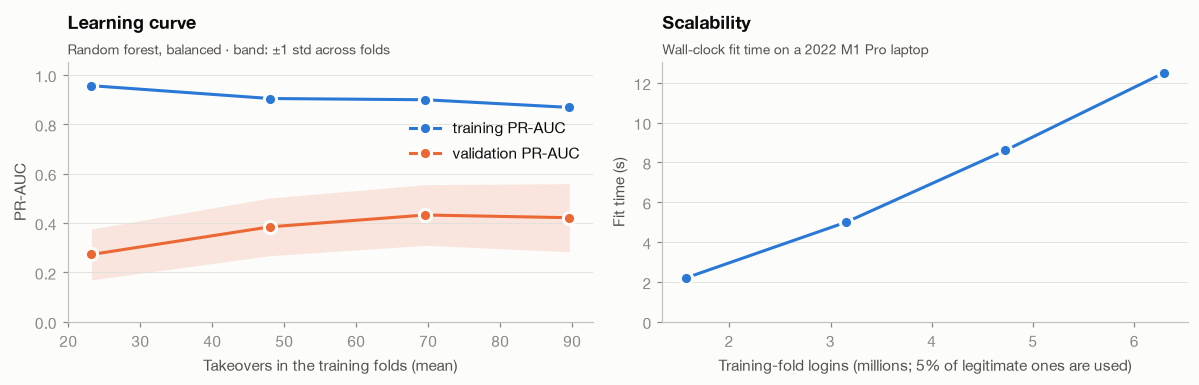

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
x = curve_summary["training takeovers"]
for column, color in (("training PR-AUC", BLUE), ("validation PR-AUC", ORANGE)):
    ax1.plot(
        x,
        curve_summary[column],
        "o-",
        color=color,
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
        label=column,
    )
ax1.fill_between(
    x,
    curve_summary["validation PR-AUC"] - curve_summary["validation std"],
    curve_summary["validation PR-AUC"] + curve_summary["validation std"],
    color=ORANGE,
    alpha=0.15,
    linewidth=0,
)
ax1.set_ylim(0, 1.05)
ax1.set_xlabel("Takeovers in the training folds (mean)")
ax1.set_ylabel("PR-AUC")
ax1.grid(axis="y")
ax1.legend(loc="center right", bbox_to_anchor=(1.0, 0.7))
ax1.set_title("Learning curve", pad=22)
subtitle(ax1, "Random forest, balanced · band: ±1 std across folds")
ax2.plot(
    curve_summary["training logins"] / 1e6,
    curve_summary["fit seconds"],
    "o-",
    color=BLUE,
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
ax2.set_ylim(0, None)
ax2.set_xlabel("Training-fold logins (millions; 5% of legitimate ones are used)")
ax2.set_ylabel("Fit time (s)")
ax2.grid(axis="y")
ax2.set_title("Scalability", pad=22)
subtitle(ax2, "Wall-clock fit time on a 2022 M1 Pro laptop")
plt.tight_layout()
plt.show()

**Reading (learning curves).** Validation PR-AUC rises from 0.27 with ~23 training takeovers to 0.38 with ~48
and ~0.43 with ~70, then levels off (0.42 with all ~90; the fold-to-fold spread, ±0.10–0.14, is larger than the
last step). Training PR-AUC stays far higher (0.87–0.96): a forest nearly memorises its training takeovers, which
is normal for this model family and not by itself a problem, since validation keeps up with it until ~70
takeovers. **Diagnosis:** no underfitting (the model has the capacity, unlike the logistic regression of issue #5),
some variance from so few positives, and more *labels* would help most at the small end — beyond ~70 takeovers the
gain is within noise. Fit time grows linearly with the data, about 12 s for a full training fold.

**Finalists on all 15 folds.** The rule, coded before running (cell below): among the models whose pooled
interval lies above the bar (0.050) and whose recall at 1% is ≥ 0.80, select the **highest mean PR-AUC over the 15
folds**. Default settings are kept for both families: no grid point above beats its default by more than the
noise (the random forest with leaf size 2 reached 0.451 on repeat 0, inside the default's interval; LightGBM's
default is the best of its grid).

In [19]:
FINALISTS = {
    "logistic regression (bar)": (candidate("logistic regression"), BASE, "logistic regression"),
    "random forest + campaign + travel, balanced": (
        candidate("random forest", balance_campaign=True),
        NEW,
        "random forest + campaign + travel, campaign-balanced",
    ),
    "random forest + campaign + travel": (
        candidate("random forest"),
        NEW,
        "random forest + campaign + travel",
    ),
    "LightGBM + campaign + travel": (candidate("LightGBM"), NEW, "LightGBM + campaign + travel"),
}
for label, (fitter, columns, already_run) in FINALISTS.items():
    for repeat in range(N_REPEATS):
        run(
            label,
            fitter,
            columns,
            repeat=repeat,
            step="finalists",
            reuse=already_run if repeat == 0 else None,
        )
finalists = (
    pl.DataFrame([r for r in results if r["step"] == "finalists"])
    .group_by("experiment", maintain_order=True)
    .agg(
        pl.col("pr_auc").mean().alias("pr_auc (15 folds)"),
        pl.col("pr_auc_std").mean().alias("std within repeat"),
        pl.col("pr_auc").std().alias("std across repeats"),
        pl.col("recall_0_1pct").mean(),
        pl.col("recall_1pct").mean(),
        pl.col("precision_1pct").mean(),
        pl.col("pr_auc_romania").mean(),
        pl.col("pr_auc_other").mean(),
        pl.col("recall_1pct_romania").mean(),
        pl.col("recall_1pct_other").mean(),
        pl.col("pooled_low").mean(),
        pl.col("pooled_high").mean(),
    )
    .with_columns(pl.col(pl.Float64).round(4))
)
finalists

experiment,pr_auc (15 folds),std within repeat,std across repeats,recall_0_1pct,recall_1pct,precision_1pct,pr_auc_romania,pr_auc_other,recall_1pct_romania,recall_1pct_other,pooled_low,pooled_high
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""logistic regression (bar)""",0.0426,0.0248,0.0086,0.5274,0.8044,0.0011,0.0264,0.0062,0.9677,0.6,0.0117,0.0523
"""random forest + campaign + travel, balanced""",0.4264,0.1389,0.009,0.8158,0.8935,0.0013,0.5141,0.1286,1.0,0.76,0.3306,0.5052
"""random forest + campaign + travel""",0.4243,0.1473,0.0105,0.8069,0.9023,0.0013,0.5237,0.1149,0.9946,0.7867,0.3284,0.503
"""LightGBM + campaign + travel""",0.4443,0.1504,0.0201,0.8038,0.8963,0.0013,0.5528,0.0979,0.9892,0.7667,0.3383,0.5094


In [20]:
BAR, MIN_RECALL_1PCT = 0.050, 0.80  # issue #5: upper end of the baseline interval; its recall at 1%
chosen = finalists.filter(
    (pl.col("pooled_low") > BAR) & (pl.col("recall_1pct") >= MIN_RECALL_1PCT)
).sort("pr_auc (15 folds)", descending=True)
best = chosen["experiment"][0]
print("selected:", best)
chosen.select("experiment", "pr_auc (15 folds)", "pr_auc_other", "recall_1pct", "recall_1pct_other")

selected: LightGBM + campaign + travel


experiment,pr_auc (15 folds),pr_auc_other,recall_1pct,recall_1pct_other
str,f64,f64,f64,f64
"""LightGBM + campaign + travel""",0.4443,0.0979,0.8963,0.7667
"""random forest + campaign + travel, balanced""",0.4264,0.1286,0.8935,0.76
"""random forest + campaign + travel""",0.4243,0.1149,0.9023,0.7867


**Reading (selection).** **LightGBM with the `campaign` and `travel` features** is selected: mean PR-AUC
0.444 over the 15 folds, ~10× the logistic regression (0.043), recall 80% at a 0.1% budget and 90% at 1%. The three
tree finalists are **statistically tied** — their difference (0.42–0.44) is far smaller than the fold-to-fold
spread (±0.14–0.15) — and they trade places on the sub-groups: the balanced random forest ranks the non-Romania
takeovers best (PR-AUC 0.129 vs 0.098), LightGBM is best on Romania. LightGBM is also the lightest to train (3 s
on the whole development side) and to store (0.6 MB). Precision stays low at every budget (0.13% at 1%: about one
real takeover per 770 alerts), so issue #7 studies thresholds and their cost carefully.

## 💾 Train the selected model and save it

The selected configuration is refitted on the **whole development side** and saved as a `.joblib` pipeline
(preprocessing + model) in `data/06_models/` (gitignored), with a metadata file. Its out-of-fold development scores
(repeat 0) are saved in `data/07_model_output/`: issue #7 chooses alert thresholds on them, so the test side is
used only once, for the final measurement.

In [21]:
fitter, columns, _ = FINALISTS[best]
model_name = "random forest" if best.startswith("random forest") else "LightGBM"
balanced = best.endswith("balanced")
start = time.perf_counter()
pipeline = train_supervised(model_name, dev, columns, balance_campaign=balanced)
print(
    f"refitted on {dev.height:,} logins ({int(y.sum())} takeovers) in {time.perf_counter() - start:.0f} s"
)

models_dir, output_dir = data_dir / "06_models", data_dir / "07_model_output"
models_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)
joblib.dump(pipeline, models_dir / f"{config.name}_model.joblib")
summary = finalists.filter(pl.col("experiment") == best).row(0, named=True)
metadata = {
    "dataset": config.name, "selected": best, "model": model_name, "campaign_balanced": balanced,
    "columns": columns, "negative_share": 0.05, "trained_on": "development side (80% of users)",
    "cv_15_folds": {k: v for k, v in summary.items() if k != "experiment"},
}  # fmt: skip
(models_dir / f"{config.name}_model.json").write_text(json.dumps(metadata, indent=2))
pl.DataFrame({"event_id": dev["event_id"], "score": oof_cache[f"{best} · repeat 0"]}).write_parquet(
    output_dir / f"{config.name}_dev_oof.parquet"
)
print(
    "saved:",
    *(p.relative_to(REPO_ROOT) for p in sorted(models_dir.glob(f"{config.name}_model.*"))),
    sep="\n  ",
)

refitted on 7,868,084 logins (112 takeovers) in 3 s


saved:
  data/06_models/rba_model.joblib
  data/06_models/rba_model.json


## ✅ Conclusions

* **Trees beat the bar by an order of magnitude.** Every tree-based family reaches PR-AUC ≈ 0.4 on the development
  folds against 0.03–0.04 for the logistic regression; the implementation (random forest, scikit-learn boosting,
  LightGBM, XGBoost) matters much less than the move away from a linear model. **Selected: LightGBM + `campaign` +
  `travel`**, PR-AUC 0.444 on 15 folds, recall 90% at a 1% budget, tied with two random-forest variants.
* **Labels beat no labels.** Isolation Forest without labels stays below even the logistic regression; the ~100
  confirmed takeovers carry most of the information. PU bagging adds cost for at most a small, non-significant gain.
* **One campaign is most of the labels.** The model still detects it when it is hidden from training, so it is not
  memorising "Romania"; but the other, heterogeneous takeovers generalise much less (hidden, their PR-AUC falls to
  0.01). Balancing the campaign improves their ranking only partly.
* **The useful signals are behavioural and global**: novelty for the user, global rarity (essential: −41% without
  it), attacker infrastructure and dormant accounts. RTT and the synthesis artefacts add nothing, as their origin
  predicts.
* **Learning curves**: validation improves with labels up to ~70 takeovers, then levels off within noise; the forest
  memorises its training takeovers but generalises up to that point.
* **The weak spot** is the non-Romania takeovers: about 3 in 4 are caught at a 1% budget, with low precision.
  Issue #7 measures the selected model **once** on the test side, chooses thresholds on the development scores
  saved above, and analyses the errors.

Numbers in this notebook are development-side, out-of-fold estimates; the final, unbiased numbers come from the test
side in issue #7.